In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/pankrzysiu/cifar10-python/cifar-10-python.tar.gz
/kaggle/input/datasets/pankrzysiu/cifar10-python/cifar-10-batches-py/data_batch_1
/kaggle/input/datasets/pankrzysiu/cifar10-python/cifar-10-batches-py/data_batch_2
/kaggle/input/datasets/pankrzysiu/cifar10-python/cifar-10-batches-py/batches.meta
/kaggle/input/datasets/pankrzysiu/cifar10-python/cifar-10-batches-py/test_batch
/kaggle/input/datasets/pankrzysiu/cifar10-python/cifar-10-batches-py/data_batch_3
/kaggle/input/datasets/pankrzysiu/cifar10-python/cifar-10-batches-py/data_batch_5
/kaggle/input/datasets/pankrzysiu/cifar10-python/cifar-10-batches-py/data_batch_4
/kaggle/input/datasets/pankrzysiu/cifar10-python/cifar-10-batches-py/readme.html


# 0: Setup

In [21]:
import os
import pickle
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as T

# 1: The Residual Block (CIFAR version)
## Concept

For CIFAR, the paper uses a stack of 6n+2 weighted layers: 1 initial conv + 3 stages of 2n layers each (so n residual blocks per stage) + a final FC layer. Each stage operates at a fixed spatial resolution: 32×32 → 16×16 → 8×8, with channel counts 16 → 32 → 64.

Each residual block here is the basic block (not bottleneck — bottlenecks only kick in for the deeper ImageNet models):

x → [3x3 conv, BN, ReLU] → [3x3 conv, BN] → add(x) → ReLU

Two situations for the shortcut:

Same shape (stride=1, channels unchanged): shortcut is just x — pure identity, zero extra params.
Downsampling (first block of a new stage, stride=2, channels double): x can't be added directly since shapes mismatch. The paper's CIFAR experiments use Option A: identity-map via strided subsampling + zero-pad the extra channels — literally zero extra parameters. This is a deliberate design choice to keep the plain-vs-residual comparison completely fair (same param count).

In [3]:
class BasicBlock(nn.Module):
    """
    CIFAR-style residual block (used in ResNet-20/32/44/56/110).
    Two 3x3 convs, identity or zero-padded shortcut (Option A).
    """
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3,
                                stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)

        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3,
                                stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

        self.relu = nn.ReLU(inplace=True)

        # Shortcut connection
        self.shortcut = nn.Identity()
        if stride != 1 or in_channels != out_channels:
            # Option A: identity mapping via stride-2 subsampling (slicing)
            # + zero-padding the extra channels. No extra parameters.
            pad_channels = out_channels - in_channels
            self.shortcut = LambdaLayer(
                lambda x: F.pad(
                    x[:, :, ::stride, ::stride],       # spatial subsample
                    (0, 0, 0, 0, 0, pad_channels),     # pad channel dim
                    mode="constant", value=0
                )
            )

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + self.shortcut(x)
        out = self.relu(out)
        return out

In [4]:
class LambdaLayer(nn.Module):
    """Small helper to wrap an arbitrary function as an nn.Module."""
    def __init__(self, fn):
        super().__init__()
        self.fn = fn

    def forward(self, x):
        return self.fn(x)

In [5]:
# Case 1: same in/out channels, stride 1 (identity shortcut)
block1 = BasicBlock(in_channels=16, out_channels=16, stride=1)
x1 = torch.randn(8, 16, 32, 32)
out1 = block1(x1)
print("Same-dim block:", x1.shape, "->", out1.shape)  # expect (8,16,32,32) -> (8,16,32,32)

# Case 2: downsampling block, channels double, spatial halves
block2 = BasicBlock(in_channels=16, out_channels=32, stride=2)
x2 = torch.randn(8, 16, 32, 32)
out2 = block2(x2)
print("Downsample block:", x2.shape, "->", out2.shape)  # expect (8,16,32,32) -> (8,32,16,16)

Same-dim block: torch.Size([8, 16, 32, 32]) -> torch.Size([8, 16, 32, 32])
Downsample block: torch.Size([8, 16, 32, 32]) -> torch.Size([8, 32, 16, 16])


# 2: The Full CIFAR ResNet
## Concept

Now we stack BasicBlocks into the full network. Recall the architecture table from Section 4.2:

output map size	32×32	16×16	8×8
layers	1+2n	2n	2n
filters	16	32	64

For n=3 (ResNet-20): 1 initial conv + 3 stages of 2n=6 layers each (= 3 residual blocks per stage, since each BasicBlock has 2 conv layers) + 1 FC layer = 1 + 3×6 + 1 = 20 layers. That's where "20-layer" comes from.

Structure:

Stem: one 3×3 conv, 16 filters, stride 1, followed by BN+ReLU (no initial max-pool — that's an ImageNet-specific detail; CIFAR images are already tiny at 32×32).
Stage 1: n blocks, 16→16 channels, stride 1 throughout (stays at 32×32).
Stage 2: n blocks, first block does 16→32 with stride 2 (downsample to 16×16), rest are 32→32 stride 1.
Stage 3: n blocks, first block does 32→64 with stride 2 (downsample to 8×8), rest are 64→64 stride 1.
Head: global average pool → flatten → FC to num_classes (10 for CIFAR-10).

In [6]:
class ResNetCIFAR(nn.Module):
    def __init__(self, n=3, num_classes=10):
        """
        n: number of residual blocks per stage.
        Total depth = 6n + 2.
        n=3  -> ResNet-20
        n=5  -> ResNet-32
        n=9  -> ResNet-56
        n=18 -> ResNet-110
        """
        super().__init__()
        self.in_channels = 16

        # Stem: single 3x3 conv, no max-pool (unlike ImageNet ResNets)
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(16)
        self.relu = nn.ReLU(inplace=True)

        # Three stages
        self.stage1 = self._make_stage(out_channels=16, num_blocks=n, stride=1)
        self.stage2 = self._make_stage(out_channels=32, num_blocks=n, stride=2)
        self.stage3 = self._make_stage(out_channels=64, num_blocks=n, stride=2)

        self.avgpool = nn.AdaptiveAvgPool2d(1)  # global average pool -> (B, 64, 1, 1)
        self.fc = nn.Linear(64, num_classes)

        self._initialize_weights()

    def _make_stage(self, out_channels, num_blocks, stride):
        # Only the first block in a stage downsamples/changes channels;
        # the rest keep stride=1 and in_channels == out_channels.
        strides = [stride] + [1] * (num_blocks - 1)
        layers = []
        for s in strides:
            layers.append(BasicBlock(self.in_channels, out_channels, stride=s))
            self.in_channels = out_channels
        return nn.Sequential(*layers)

    def _initialize_weights(self):
        # He initialization, as specified in the paper (ref [13])
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.stage1(out)
        out = self.stage2(out)
        out = self.stage3(out)
        out = self.avgpool(out)
        out = torch.flatten(out, 1)
        out = self.fc(out)
        return out


def resnet20(num_classes=10):
    return ResNetCIFAR(n=3, num_classes=num_classes)

In [7]:
model = resnet20(num_classes=10)

# Shape check
x = torch.randn(8, 3, 32, 32)
out = model(x)
print("Input:", x.shape, "-> Output:", out.shape)  # expect (8, 3, 32, 32) -> (8, 10)

# Param count check
num_params = sum(p.numel() for p in model.parameters())
print(f"Total params: {num_params:,}  (paper reports ~0.27M for ResNet-20)")

Input: torch.Size([8, 3, 32, 32]) -> Output: torch.Size([8, 10])
Total params: 269,722  (paper reports ~0.27M for ResNet-20)


In [24]:
CIFAR10_ROOT = "/kaggle/input/datasets/pankrzysiu/cifar10-python/cifar-10-batches-py"

print(os.listdir(CIFAR10_ROOT))  # should list data_batch_1..5, test_batch, batches.meta, readme.html

def _unpickle(file_path):
    with open(file_path, "rb") as f:
        return pickle.load(f, encoding="bytes")

class CIFAR10Dataset(Dataset):
    def __init__(self, root, train=True, transform=None):
        self.transform = transform

        if train:
            batch_files = [f"data_batch_{i}" for i in range(1, 6)]
        else:
            batch_files = ["test_batch"]

        images, labels = [], []
        for bf in batch_files:
            batch = _unpickle(os.path.join(root, bf))
            images.append(batch[b"data"])
            labels.extend(batch[b"labels"])

        images = np.concatenate(images, axis=0)               # (N, 3072)
        images = images.reshape(-1, 3, 32, 32)                # (N, 3, 32, 32) - CHW
        images = images.transpose(0, 2, 3, 1)                 # (N, 32, 32, 3) - HWC, uint8

        self.images = images
        self.labels = np.array(labels, dtype=np.int64)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        img = self.images[idx]           # (32, 32, 3) uint8 numpy array (HWC)
        label = int(self.labels[idx])
    
        if self.transform:
            img = self.transform(img)    # ToPILImage handles HWC numpy correctly
    
        return img, label

['data_batch_1', 'data_batch_2', 'batches.meta', 'test_batch', 'data_batch_3', 'data_batch_5', 'data_batch_4', 'readme.html']


In [25]:
# CIFAR-10 per-channel mean/std (standard, widely-used values)
CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR10_STD  = (0.2470, 0.2435, 0.2616)

train_transform = T.Compose([
    T.ToPILImage(),                          # ensure PIL ops run on raw uint8 images
    T.Pad(4, padding_mode="reflect"),         # 4px padding each side -> 40x40
    T.RandomCrop(32),                         # random 32x32 crop from padded image
    T.RandomHorizontalFlip(),                 # random horizontal flip
    T.ToTensor(),                             # -> float tensor in [0,1]
    T.Normalize(CIFAR10_MEAN, CIFAR10_STD),   # per-channel mean/std normalization
])

test_transform = T.Compose([
    T.ToPILImage(),
    T.ToTensor(),
    T.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])

train_dataset = CIFAR10Dataset(CIFAR10_ROOT, train=True, transform=train_transform)
test_dataset = CIFAR10Dataset(CIFAR10_ROOT, train=False, transform=test_transform)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True,
                           num_workers=2, pin_memory=True, drop_last=True)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False,
                          num_workers=2, pin_memory=True)

print(f"Train samples: {len(train_dataset)}, Test samples: {len(test_dataset)}")
images, labels = next(iter(train_loader))
print("Batch shape:", images.shape)          # expect (128, 3, 32, 32)
print("Label shape:", labels.shape)          # expect (128,)
print("Labels sample:", labels[:10].tolist())
print("Pixel range:", images.min().item(), "to", images.max().item())
print("Pixel mean (near 0):", images.mean().item())

Train samples: 50000, Test samples: 10000
Batch shape: torch.Size([128, 3, 32, 32])
Label shape: torch.Size([128])
Labels sample: [0, 6, 3, 3, 4, 2, 0, 9, 8, 4]
Pixel range: -1.9894737005233765 to 2.12648868560791
Pixel mean (near 0): 0.06453988701105118


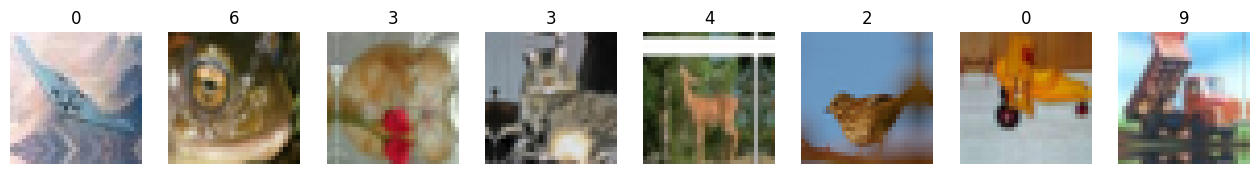

In [26]:
import matplotlib.pyplot as plt

def denormalize(img_tensor):
    mean = torch.tensor(CIFAR10_MEAN).view(3, 1, 1)
    std = torch.tensor(CIFAR10_STD).view(3, 1, 1)
    return (img_tensor * std + mean).clamp(0, 1)

fig, axes = plt.subplots(1, 8, figsize=(16, 2.5))
for i, ax in enumerate(axes):
    ax.imshow(denormalize(images[i]).permute(1, 2, 0).numpy())
    ax.set_title(int(labels[i]))
    ax.axis("off")
plt.show()

In [27]:
import time
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

model = resnet20(num_classes=10).to(device)
criterion = nn.CrossEntropyLoss()

optimizer = optim.SGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=1e-4)
scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[32000, 48000], gamma=0.1)

TOTAL_ITERS = 64000

Device: cuda


In [28]:
def train_one_epoch(model, loader, optimizer, scheduler, criterion, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        scheduler.step()                      # per-ITERATION, matching the paper's schedule

        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += images.size(0)
    return running_loss / total, 100.0 * (1 - correct / total)   # loss, train error %


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        outputs = model(images)
        loss = criterion(outputs, labels)

        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += images.size(0)
    return running_loss / total, 100.0 * (1 - correct / total)   # loss, test error %

In [29]:
test_model = resnet20().to(device)
test_opt = optim.SGD(test_model.parameters(), lr=0.1, momentum=0.9)

imgs, lbls = next(iter(train_loader))
imgs, lbls = imgs.to(device), lbls.to(device)

test_model.train()
for step in range(100):
    test_opt.zero_grad()
    out = test_model(imgs)
    loss = criterion(out, lbls)
    loss.backward()
    test_opt.step()
    if step % 20 == 0 or step == 99:
        acc = (out.argmax(1) == lbls).float().mean().item() * 100
        print(f"step {step:3d} | loss {loss.item():.4f} | acc {acc:.1f}%")

del test_model, test_opt

step   0 | loss 2.5095 | acc 6.2%
step  20 | loss 0.7453 | acc 75.0%
step  40 | loss 0.0134 | acc 100.0%
step  60 | loss 0.0008 | acc 100.0%
step  80 | loss 0.0004 | acc 100.0%
step  99 | loss 0.0003 | acc 100.0%


## Step 5: Full Training Run
Concept

Three things shape this cell given your weekly GPU quota:

Checkpoint every epoch, with resume. If the session dies or you hit a time limit, you restart from the last saved epoch instead of from zero. The checkpoint holds model, optimizer, scheduler (so the iteration-based LR schedule resumes at the right point), and the metric history.
Log per-epoch metrics (train/test error and loss) so we can plot curves like Figure 6.
Report the final-epoch test error, not the best one. Picking the best epoch by test error is selecting on the test set, which flatters the result. The paper trains to a fixed stop point and reports that, so we do the same.

Epochs: 64000 / 390 ≈ 164, so we train 164 epochs (63,960 iterations), which matches the paper’s stop point to within a fraction of an epoch.

In [30]:
EPOCHS = 164
CKPT_PATH = "/kaggle/working/resnet20_cifar10_ckpt.pt"

history = {"train_loss": [], "train_err": [], "test_loss": [], "test_err": []}
start_epoch = 0

# Resume if a checkpoint exists (e.g. after a session restart)
if os.path.exists(CKPT_PATH):
    ckpt = torch.load(CKPT_PATH, map_location=device)
    model.load_state_dict(ckpt["model"])
    optimizer.load_state_dict(ckpt["optimizer"])
    scheduler.load_state_dict(ckpt["scheduler"])
    history = ckpt["history"]
    start_epoch = ckpt["epoch"] + 1
    print(f"Resumed from epoch {start_epoch}")

for epoch in range(start_epoch, EPOCHS):
    t0 = time.time()
    tr_loss, tr_err = train_one_epoch(model, train_loader, optimizer, scheduler, criterion, device)
    te_loss, te_err = evaluate(model, test_loader, criterion, device)

    history["train_loss"].append(tr_loss); history["train_err"].append(tr_err)
    history["test_loss"].append(te_loss);  history["test_err"].append(te_err)

    torch.save({
        "epoch": epoch,
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "history": history,
    }, CKPT_PATH)

    lr = optimizer.param_groups[0]["lr"]
    print(f"Epoch {epoch+1:3d}/{EPOCHS} | lr {lr:.4f} | "
          f"train loss {tr_loss:.4f} err {tr_err:5.2f}% | "
          f"test loss {te_loss:.4f} err {te_err:5.2f}% | {time.time()-t0:.1f}s")

print(f"\nFinal test error: {history['test_err'][-1]:.2f}%  (paper: 8.75%)")

Epoch   1/164 | lr 0.1000 | train loss 1.6331 err 61.56% | test loss 1.5310 err 54.93% | 22.0s
Epoch   2/164 | lr 0.1000 | train loss 1.1367 err 40.75% | test loss 1.2280 err 42.40% | 21.8s
Epoch   3/164 | lr 0.1000 | train loss 0.8982 err 31.91% | test loss 0.9940 err 33.81% | 21.8s
Epoch   4/164 | lr 0.1000 | train loss 0.7601 err 26.65% | test loss 0.8466 err 28.18% | 21.4s
Epoch   5/164 | lr 0.1000 | train loss 0.6832 err 23.77% | test loss 0.7839 err 26.87% | 21.5s
Epoch   6/164 | lr 0.1000 | train loss 0.6163 err 21.40% | test loss 0.7194 err 24.00% | 21.5s
Epoch   7/164 | lr 0.1000 | train loss 0.5751 err 19.81% | test loss 0.5633 err 19.59% | 21.6s
Epoch   8/164 | lr 0.1000 | train loss 0.5372 err 18.61% | test loss 0.6375 err 21.56% | 21.5s
Epoch   9/164 | lr 0.1000 | train loss 0.5189 err 18.17% | test loss 0.5667 err 19.16% | 21.4s
Epoch  10/164 | lr 0.1000 | train loss 0.4967 err 17.11% | test loss 0.6502 err 21.57% | 21.4s
Epoch  11/164 | lr 0.1000 | train loss 0.4675 err 

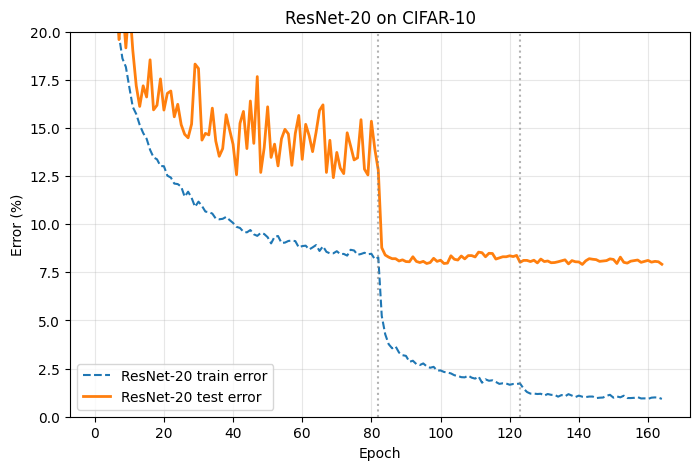

Final train error: 0.93% | Final test error: 7.92%


In [31]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["test_err"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_err"], "--", label="ResNet-20 train error")
plt.plot(epochs, history["test_err"], "-", linewidth=2, label="ResNet-20 test error")
plt.axvline(82, color="gray", linestyle=":", alpha=0.6)
plt.axvline(123, color="gray", linestyle=":", alpha=0.6)
plt.ylim(0, 20)
plt.xlabel("Epoch")
plt.ylabel("Error (%)")
plt.title("ResNet-20 on CIFAR-10")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Final train error: {history['train_err'][-1]:.2f}% | Final test error: {history['test_err'][-1]:.2f}%")